### **Modelling football game using a Poisson model (Q1)**

In [1]:
#function simulation for a single game
import numpy as np

# set up RNG with seed
seedVal = 62354124
rng = np.random.default_rng (seedVal)

def result(lam_a, lam_b):
    #x_a and x_b be the number of goals scored by Team A and Team B respectively in a single game
    x_a = rng.poisson (lam=lam_a)
    x_b = rng.poisson (lam=lam_b)
    if x_a > x_b:
        winner = 'A'
    elif x_a < x_b:
        winner = 'B'
    else:
        winner = 'D'
    return x_a, x_b, winner

In [2]:
# Monte Carlo simulation
# proportion of games won by Team A
numTrials = 1000
numWins = 0
for i in range(numTrials):
    if result (lam_a = 1.5, lam_b = 2)[2] == 'A':
        numWins += 1
        
print (f'proportion of games won by Team A is {numWins / numTrials} ({numWins} out of {numTrials} trials)')


proportion of games won by Team A is 0.311 (311 out of 1000 trials)


### **Fitting a Poisson model by maximum likelihood (Q2 + Q3)**

In [3]:
import pandas as pd

In [4]:
## set up pandas data frame
data = {
    'TeamA':[],
    'TeamB':[],
    'goalA':[],
    'goalB':[]
}

D = pd.DataFrame(data)

teams = ['W', 'X', 'Y', 'Z']
strengths = [2.72, 1.65, 2.12, 3.49]
N = 10

def goals(TeamNo):
    x = rng.poisson (lam=strengths[TeamNo])
    return x

## filling in data
for i in range(N-2):
    a = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
    b = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
    while a == b:
        b = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
    D.loc[i] = [teams[a[0]], teams[b[0]], goals(a[0]), goals(b[0])]

## adding two matches to ensure every team has played at least one game
D.loc[i+1] = [teams[0], teams[1], goals(0), goals(1)]
D.loc[i+2] = [teams[2], teams[3], goals(2), goals(3)]
print(D)

  TeamA TeamB  goalA  goalB
0     X     W      2      2
1     W     X      1      2
2     Z     Y      4      3
3     Z     Y      4      1
4     W     Y      4      3
5     X     Z      0      1
6     W     X      2      1
7     X     Y      1      6
8     W     X      2      1
9     Y     Z      3      6


In [5]:
## calculating mean goal scoring rate
mean = {}

for i in range(len(teams)):
    ## finding all matches played by the i'th team
    numMatches = 0
    numGoals = 0
    for team, goal in zip(D['TeamA'], D['goalA']):
        if team == teams[i]:
            numMatches += 1
            numGoals += goal
    for team, goal in zip(D['TeamB'], D['goalB']):
        if team == teams[i]:
            numMatches += 1
            numGoals += goal
    ## filling data for the i'th team
    mean[f'{teams[i]}'] = numGoals/numMatches

print(mean)

{'W': 2.2, 'X': 1.1666666666666667, 'Y': 3.2, 'Z': 3.75}


In [6]:
from scipy.stats import poisson
import scipy.optimize as opt

## calculate log likelihood
def logLike(strengths, dataset, teams):
    ##convert strength to dictionary for easier access of data
    strengthDic = {
        team: strength
        for team, strength in zip (teams, strengths)
    }
    
    l = 0
    for si, ti, ui, vi in zip(dataset['TeamA'], dataset['TeamB'], dataset['goalA'], dataset['goalB']):
        l = l + poisson.logpmf(k=ui, mu=strengthDic[si]) + poisson.logpmf(k=vi, mu=strengthDic[ti])
    return -l

## calculate AICc
def funAICc(k, N, l):
    AICc = 2*k - 2*l + 2*k*(k+1)/(N-k-1)
    return AICc

w = opt.minimize(fun=logLike, x0=strengths, args=(D, teams))
if w.success:
    lam_w = w.x[0]
    lam_x = w.x[1]
    lam_y = w.x[2]
    lam_z = w.x[3]
    AICc = funAICc(4, 20, -1*w.fun)
    print(f"Maximum likelihood estimate: lam_w={lam_w:.3f}, lam_x={lam_x:.3f}, lam_y={lam_y:.3f}, lam_z={lam_z:.3f}")
    print(f"log likelihood={-1 * w.fun:.3f}")
    print(f'AICc = {AICc:.3f}')
else:
    print("Optimisation failed")

Maximum likelihood estimate: lam_w=2.200, lam_x=1.167, lam_y=3.200, lam_z=3.750
log likelihood=-32.345
AICc = 75.356


Comment: Since the Maximum likelihood estimate is close to the mean goal scoring rate, the fitting works indeed.

## **Fitting a Poisson model as a generalised linear model (Q4)**

In [7]:
##reshape dataset D
data1 = {
    'Team':[],
    'Goals':[]
}

D1 = pd.DataFrame(data1)

for teamA, goalsA, teamB, goalsB in zip(D['TeamA'], D['goalA'], D['TeamB'], D['goalB']):
    D1.loc[len(D1)] = [teamA, goalsA]
    D1.loc[len(D1)] = [teamB, goalsB]

## fit model using Poisson regression
import statsmodels.formula.api as smf 
import statsmodels.api as sm 

Mod = smf.glm(formula = 'Goals ~ Team', 
                data = D1, 
                family = sm.families.Poisson()).fit() 
print(Mod.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  Goals   No. Observations:                   20
Model:                            GLM   Df Residuals:                       16
Model Family:                 Poisson   Df Model:                            3
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -32.345
Date:                Wed, 28 Jan 2026   Deviance:                       13.534
Time:                        13:21:41   Pearson chi2:                     12.0
No. Iterations:                     4   Pseudo R-squ. (CS):             0.3482
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.7885      0.302      2.615      0.0

In [31]:
co_w = Mod.params.iloc[0]
co_x = co_w + Mod.params.iloc[1]
co_y = co_w + Mod.params.iloc[2]
co_z = co_w + Mod.params.iloc[3]

print(f'lambda estimates: lam_w = {np.exp(co_w):.3f}, lam_x = {np.exp(co_x):.3f}, lam_y = {np.exp(co_y):.3f}, lam_z = {np.exp(co_z):.3f}')
print(f'AICc = {AICc:.3f}')

lambda estimates: lam_w = 2.200, lam_x = 1.167, lam_y = 3.200, lam_z = 3.750
AICc = 75.356


Comment:
1. lambda estimates identical to results obtained in Q3.
2. Since Log likelihood is identical to results obtained in Q3, and parameters (4) and number of observations (20) have not changed, AICc should also be the same as in Q3

## **Parameterising the mean number of goals per match in terms of team strength (Q5)**

In [9]:
## adding ranks

rankDict = {
    team: rank
    for team, rank in zip (teams, [2, 4, 3, 1])
}

rankList = []
for team in D1.Team:
    rankList.append(rankDict[team])

D1['Rank']= rankList
print (D1)

   Team  Goals  Rank
0     X      2     4
1     W      2     2
2     W      1     2
3     X      2     4
4     Z      4     1
5     Y      3     3
6     Z      4     1
7     Y      1     3
8     W      4     2
9     Y      3     3
10    X      0     4
11    Z      1     1
12    W      2     2
13    X      1     4
14    X      1     4
15    Y      6     3
16    W      2     2
17    X      1     4
18    Y      3     3
19    Z      6     1


In [10]:
ModRank = smf.glm(formula = 'Goals ~ Rank', 
                data = D1, 
                family = sm.families.Poisson()).fit() 
print(ModRank.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  Goals   No. Observations:                   20
Model:                            GLM   Df Residuals:                       18
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -34.279
Date:                Wed, 28 Jan 2026   Deviance:                       17.401
Time:                        13:21:41   Pearson chi2:                     17.1
No. Iterations:                     4   Pseudo R-squ. (CS):             0.2092
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.5880      0.332      4.784      0.0

In [11]:
print(
    f'α = {ModRank.params.iloc[0]:.3f} \nβ = {ModRank.params.iloc[1]:.3f} \nLog likelihood (l) = {ModRank.llf:.3f} \nNo. Observations(N) = 20 \nparameters (k) = 2'
)

α = 1.588 
β = -0.279 
Log likelihood (l) = -34.279 
No. Observations(N) = 20 
parameters (k) = 2


In [12]:
print(f'AICc of the model: {funAICc(2, 20, ModRank.llf)}')
print(f'delta_AICc:{AICc-funAICc(2, 20, ModRank.llf)}')

AICc of the model: 73.26317955645605
delta_AICc:2.0931710024599397


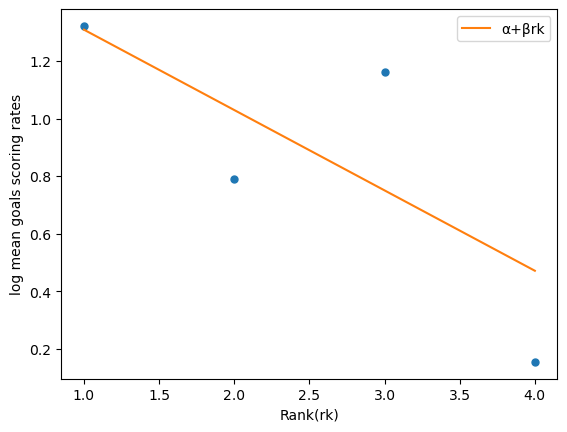

In [32]:
## plot scattered graph to check the model
from matplotlib import pyplot as plt

x1 = [2, 4, 3, 1]
meanScore = pd.DataFrame(mean, index=[0])
y1 = np.log(meanScore.loc[0])
x = np.linspace(1, 4)
y = ModRank.params.iloc[0]+ModRank.params.iloc[1]*x
plt.plot(x1, y1, linestyle="", marker = "o", markersize=5)
plt.plot(x, y, label='α+βrk')
plt.legend()
plt.xlabel('Rank(rk)')
plt.ylabel('log mean goals scoring rates')
plt.show()

Comment:
1. The scatter points (from Q3 and Q4 estimates) lie closely to the fitted regression line, which shows that the fitted model is consistent with results from Q3 and Q4.
2. The model in Q5 is more parasimonious, because it uses less paramaters (2, while Q4 uses 4). The model in Q5 also has smaller AICc value, especially because the AICc difference between two models is 2.09(on this run, might vary in different run, for precise value please refer to the data above), showing less support for the Q4 model and indicating that Q5 model is more parasimonious.

## **Simulating a tournament (Q6)**

In [14]:
rankings = pd.read_csv('data/2024_rankings.csv')
teamID = pd.read_csv('data/2024_teamID.csv')

In [15]:
import random

def simulate_tournament(verbose = False):
    teams = rankings['Team']
    strengths = np.exp(1 - 0.05*rankings['Rank'])
    
    def goal(teamNo):
        ##since values of 'teams' changes later on, this step ensures the strength always matches the correct team
        a = rankings.loc[rankings['Team'] == teams[teamNo]]['Rank'].index
        x = rng.poisson (lam=strengths[a])
        return x[0]
    
    ##bye teams
    bye = []
    k = random.sample(range(0, 24), 8)
    for i in k:
       bye.append(teams[i])
    
    if verbose:               
        print(f'Teams given a bye to next round: {bye}\n')
    
    ##Round one
    dataOne = {
        'TeamA':[],
        'TeamB':[],
        'goalA':[],
        'goalB':[]
    }
    
    One = pd.DataFrame(dataOne)
    
    for i in range(8):
        x = [0]
        y = [0]
        while teams[x[0]] in bye or teams[y[0]] in bye or teams[x[0]] in One[['TeamA','TeamB']].values or teams[y[0]] in One[['TeamA','TeamB']].values or x==y:
            x = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
            y = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
        One.loc[i] = [teams[x[0]], teams[y[0]], goal(x[0]), goal(y[0])]
    if verbose:   
        print(f'Match result for Round 1:\n{One}\n')
    
    from copy import deepcopy
    teams = deepcopy(bye)
    
    ## iterating for 4 more rounds
    for j in range(4):
        ##decide teams for the next round
        for i in range(len(One)):
            if One['goalA'][i] > One['goalB'][i]:
                teams.append(One['TeamA'][i])
            elif One['goalA'][i] < One['goalB'][i]:
                teams.append(One['TeamB'][i])
            else:
                u = rng.binomial(size=1, n=1, p= 0.5)
                if u == 0:
                   teams.append(One['TeamA'][i])
                else:
                   teams.append(One['TeamB'][i])
        if verbose:   
            print (f'Teams that enter the next round:{teams}\n')
       
        ##simulating match result for the next round
        dataOne = {
            'TeamA':[],
            'TeamB':[],
            'goalA':[],
            'goalB':[]
        }
        
        One = pd.DataFrame(dataOne)
        
        for i in range(int(len(teams)/2)):
            x = [0]
            y = [0]
            while teams[x[0]] in One[['TeamA','TeamB']].values or teams[y[0]] in One[['TeamA','TeamB']].values or x==y:
                x = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
                y = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
            One.loc[i] = [teams[x[0]], teams[y[0]], goal(x[0]), goal(y[0])]
        if verbose:   
            print(f'Match result for Round {j+2}:\n{One}\n')
        
        teams = []
    
    ## announce the champion
    if One['goalA'][0] > One['goalB'][0]:
        c = One['TeamA'][0]   
    elif One['goalA'][0] < One['goalB'][0]:
        c = One['TeamB'][0]
    else:
        u = rng.binomial(size=1, n=1, p= 0.5)
        if u == 0:
            c = One['TeamA'][0]  
        else:
            c = One['TeamB'][0]  
    
    if verbose:
        print(f'The champion is {c}')

    return c

simulate_tournament(verbose=True)

Teams given a bye to next round: ['France', 'Turkey', 'Belgium', 'Romania', 'Serbia', 'Italy', 'Ukraine', 'Slovakia']

Match result for Round 1:
            TeamA        TeamB  goalA  goalB
0         England     Portugal      3      1
1           Spain      Albania      3      0
2         Austria       Poland      0      0
3     Netherlands      Germany      1      4
4         Croatia      Denmark      0      0
5  Czech Republic  Switzerland      2      0
6        Slovenia      Georgia      0      0
7         Hungary     Scotland      2      1

Teams that enter the next round:['France', 'Turkey', 'Belgium', 'Romania', 'Serbia', 'Italy', 'Ukraine', 'Slovakia', 'England', 'Spain', 'Poland', 'Germany', 'Croatia', 'Czech Republic', 'Slovenia', 'Hungary']

Match result for Round 2:
            TeamA     TeamB  goalA  goalB
0         England  Slovakia      1      0
1         Ukraine   Germany      0      0
2         Hungary    France      0      3
3         Romania    Poland      0      1
4 

'France'

In [16]:
numTrials = 1000

dWinner ={
    'Team':rankings['Team'],    
    'numWins': [0]*24
}

Winner = pd.DataFrame(dWinner)

#count winners
for i in range(numTrials):
    c = simulate_tournament()
    Winner.loc[Winner['Team'] == c, 'numWins'] = Winner.loc[Winner['Team'] == c]['numWins'].values[0] + 1

#calculate probabilities
Prob = []
for x in Winner['numWins']:
    p = x/numTrials
    Prob.append(p)

Winner.insert(2, "pWins", Prob)    
print(Winner)

              Team  numWins  pWins
0          Albania        0  0.000
1          Austria        8  0.008
2          Belgium      163  0.163
3          Croatia       65  0.065
4   Czech Republic        0  0.000
5          Denmark       14  0.014
6          England      156  0.156
7           France      199  0.199
8          Georgia        0  0.000
9          Germany       19  0.019
10         Hungary        5  0.005
11           Italy       77  0.077
12     Netherlands       99  0.099
13          Poland        3  0.003
14        Portugal       89  0.089
15         Romania        4  0.004
16        Scotland        3  0.003
17          Serbia        1  0.001
18        Slovakia        0  0.000
19        Slovenia        0  0.000
20           Spain       67  0.067
21     Switzerland       22  0.022
22          Turkey        1  0.001
23         Ukraine        5  0.005


## *Part II*

In [17]:
game = pd.read_csv('data/gameData.csv')
game.head(-10)

,Year,TeamA,TeamB,GameType,Home,goalA,goalB,ExtraInfo
0,1996,England,Switzerland,Group stage,A,1,1,NaN
1,1996,Netherlands,Scotland,Group stage,NaN,0,0,NaN
2,1996,Switzerland,Netherlands,Group stage,NaN,0,2,NaN
3,1996,Scotland,England,Group stage,B,0,2,NaN
4,1996,Scotland,Switzerland,Group stage,NaN,1,0,NaN
...,...,...,...,...,...,...,...,...
242,2021,Wales,Denmark,Round of 16,NaN,0,4,NaN
243,2021,Italy,Austria,Round of 16,NaN,0,0,ET (2:1)
244,2021,Netherlands,Czech Republic,Round of 16,NaN,0,2,NaN
245,2021,Belgium,Portugal,Round of 16,NaN,1,0,NaN


In [18]:
rank = pd.read_csv('data/rankData.csv')
rank.head(-5)

,Year,Team,Rank
0,1996,Bulgaria,28
1,1996,Croatia,27
2,1996,Czech Republic,10
3,1996,Denmark,11
4,1996,England,24
...,...,...,...
118,2021,Portugal,5
119,2021,Russia,38
120,2021,Scotland,44
121,2021,Slovakia,36


In [19]:
## reorganise the data
dgame = {
    'Team':[],
    'Goal':[],
    'Home':[],
    'Neutral':[],
    'Rank':[],
    'oppRank':[]
}

Dgame = pd.DataFrame(dgame)

def homeStatsA(home):
    if home == 'A':
        x = 1
    else:
        x = 0
    return x

def homeStatsB(home):
    if home == 'B':
        x = 1
    else:
        x = 0
    return x

def nStats(home):
    if home == 'A' or home == 'B':
        x = 0
    else:
        x = 1
    return x

def searchRank(team, year):
    x = rank.loc[(rank.Team == team) & (rank.Year == year)].Rank
    return x.values[0]

for teamA, teamB, goalA, goalB, home, year in zip(game.TeamA, game.TeamB, game.goalA, game.goalB, game.Home, game.Year):
    Dgame.loc[len(Dgame)] = [teamA, goalA, homeStatsA(home), nStats(home), searchRank(teamA, year), searchRank(teamB, year)]
    Dgame.loc[len(Dgame)] = [teamB, goalB, homeStatsB(home), nStats(home), searchRank(teamB, year), searchRank(teamA, year)]

print(Dgame)

            Team  Goal  Home  Neutral  Rank  oppRank
0        England     1     1        0    24       21
1    Switzerland     1     0        0    21       24
2    Netherlands     0     0        1    13       31
3       Scotland     0     0        1    31       13
4    Switzerland     0     0        1    21       13
..           ...   ...   ...      ...   ...      ...
509        Spain     1     0        1     6        7
510      England     1     1        0     4       10
511      Denmark     1     0        0    10        4
512        Italy     1     0        0     7        4
513      England     1     1        0     4        7

[514 rows x 6 columns]


In [20]:
##model fitting
Mod5 = smf.glm(formula = 'Goal ~ Rank + oppRank + Home + Neutral', 
                data = Dgame, 
                family = sm.families.Poisson()).fit() 
print(Mod5.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                   Goal   No. Observations:                  514
Model:                            GLM   Df Residuals:                      509
Model Family:                 Poisson   Df Model:                            4
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -706.13
Date:                Wed, 28 Jan 2026   Deviance:                       575.88
Time:                        13:23:40   Pearson chi2:                     486.
No. Iterations:                     5   Pseudo R-squ. (CS):            0.09583
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0471      0.169     -0.279      0.7

In [21]:
print(f'α = {Mod5.params.iloc[0]:.3f}')
print(f'β = {Mod5.params.iloc[1]:.3f}')
print(f'γ = {Mod5.params.iloc[2]:.3f}')
print(f'vh = {Mod5.params.iloc[3]:.3f}')
print(f'vn = {Mod5.params.iloc[4]:.3f}')

α = -0.047
β = -0.018
γ = 0.009
vh = 0.645
vn = 0.352


In [33]:
def simulate_tournament2(verbose = False):
    teams = rankings['Team']
    
    def goal(teamX, teamY):
        rank = rankings.loc[rankings['Team'] == teams[teamX]]['Rank'].values[0]
        opprank = rankings.loc[rankings['Team'] == teams[teamY]]['Rank'].values[0]
        if teams[teamX] == 'Germany':
            home = 1
            neutral = 0
        elif teams[teamY] == 'Germany':
            home = 0
            neutral = 0
        else:
            home = 0
            neutral = 1
        strengths = np.exp(Mod5.params.iloc[0] + Mod5.params.iloc[1]*rank + Mod5.params.iloc[2]*opprank + Mod5.params.iloc[3]*home + Mod5.params.iloc[4]*neutral)
        x = rng.poisson (lam=strengths)
        return x
    
    ##bye teams
    bye = []
    k = random.sample(range(0, 24), 8)
    for i in k:
       bye.append(teams[i])
    
    if verbose:               
        print(f'Teams given a bye to next round: {bye}\n')
    
    ##Round one
    dataOne = {
        'TeamA':[],
        'TeamB':[],
        'goalA':[],
        'goalB':[]
    }
    
    One = pd.DataFrame(dataOne)
    
    for i in range(8):
        x = [0]
        y = [0]
        while teams[x[0]] in bye or teams[y[0]] in bye or teams[x[0]] in One[['TeamA','TeamB']].values or teams[y[0]] in One[['TeamA','TeamB']].values or x==y:
            x = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
            y = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
        One.loc[i] = [teams[x[0]], teams[y[0]], goal(x[0], y[0]), goal(y[0], x[0])]
    if verbose:   
        print(f'Match result for Round 1:\n{One}\n')
    
    from copy import deepcopy
    teams = deepcopy(bye)
    
    ## iterating for 4 more rounds
    for j in range(4):
        ##decide teams for the next round
        for i in range(len(One)):
            if One['goalA'][i] > One['goalB'][i]:
                teams.append(One['TeamA'][i])
            elif One['goalA'][i] < One['goalB'][i]:
                teams.append(One['TeamB'][i])
            else:
                u = rng.binomial(size=1, n=1, p= 0.5)
                if u == 0:
                   teams.append(One['TeamA'][i])
                else:
                   teams.append(One['TeamB'][i])
        if verbose:   
            print (f'Teams that enter the next round:{teams}\n')
       
        ##simulating match result for the next round
        dataOne = {
            'TeamA':[],
            'TeamB':[],
            'goalA':[],
            'goalB':[]
        }
        
        One = pd.DataFrame(dataOne)
        
        for i in range(int(len(teams)/2)):
            x = [0]
            y = [0]
            while teams[x[0]] in One[['TeamA','TeamB']].values or teams[y[0]] in One[['TeamA','TeamB']].values or x==y:
                x = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
                y = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
            One.loc[i] = [teams[x[0]], teams[y[0]], goal(x[0], y[0]), goal(y[0], x[0])]
        if verbose:   
            print(f'Match result for Round {j+2}:\n{One}\n')
        
        teams = []
    
    ## announce the champion
    if One['goalA'][0] > One['goalB'][0]:
        c = One['TeamA'][0]   
    elif One['goalA'][0] < One['goalB'][0]:
        c = One['TeamB'][0]
    else:
        u = rng.binomial(size=1, n=1, p= 0.5)
        if u == 0:
            c = One['TeamA'][0]  
        else:
            c = One['TeamB'][0]  
    
    if verbose:
        print(f'The champion is {c}')

    return c

simulate_tournament2(verbose=True)

Teams given a bye to next round: ['Ukraine', 'Netherlands', 'Poland', 'Germany', 'Scotland', 'Georgia', 'Hungary', 'Portugal']

Match result for Round 1:
            TeamA        TeamB  goalA  goalB
0         Denmark     Slovenia      4      1
1         Romania       Serbia      1      0
2           Spain      Albania      1      0
3        Slovakia      England      0      1
4  Czech Republic  Switzerland      1      0
5           Italy       France      3      0
6         Austria      Croatia      2      2
7         Belgium       Turkey      0      0

Teams that enter the next round:['Ukraine', 'Netherlands', 'Poland', 'Germany', 'Scotland', 'Georgia', 'Hungary', 'Portugal', 'Denmark', 'Romania', 'Spain', 'England', 'Czech Republic', 'Italy', 'Croatia', 'Belgium']

Match result for Round 2:
     TeamA           TeamB  goalA  goalB
0  Hungary        Portugal      1      5
1    Italy  Czech Republic      1      0
2   Poland         England      2      0
3  Denmark     Netherlands      

'Croatia'

In [23]:
numTrials = 1000

dWinner ={
    'Team':rankings['Team'],    
    'numWins': [0]*24
}

Winner = pd.DataFrame(dWinner)

#count winners
for i in range(numTrials):
    c = simulate_tournament2()
    Winner.loc[Winner['Team'] == c, 'numWins'] = Winner.loc[Winner['Team'] == c]['numWins'].values[0] + 1

#calculate probabilities
Prob = []
for x in Winner['numWins']:
    p = x/numTrials
    Prob.append(p)

Winner.insert(2, "pWins", Prob)    
print(Winner)

              Team  numWins  pWins
0          Albania        2  0.002
1          Austria       22  0.022
2          Belgium       87  0.087
3          Croatia       61  0.061
4   Czech Republic        7  0.007
5          Denmark       25  0.025
6          England      101  0.101
7           France      101  0.101
8          Georgia        1  0.001
9          Germany      166  0.166
10         Hungary       21  0.021
11           Italy       80  0.080
12     Netherlands       83  0.083
13          Poland        6  0.006
14        Portugal       82  0.082
15         Romania        1  0.001
16        Scotland        8  0.008
17          Serbia       16  0.016
18        Slovakia        0  0.000
19        Slovenia        1  0.001
20           Spain       75  0.075
21     Switzerland       27  0.027
22          Turkey        1  0.001
23         Ukraine       26  0.026


In [34]:
##could also count the times each team wins at each stage of the tournament
##which stays aligned with the method used in Q2 and make comparison more consisten later
numTrials = 1000

dwinCounts = {
        'Team':rankings['Team'],    
        'numWins': [0]*24
    }
    
winCounts = pd.DataFrame(dwinCounts)
         
for i in range(numTrials): 
        teams = rankings['Team']
   
        def winAdd(name):
                winCounts.loc[winCounts['Team'] == name, 'numWins'] = winCounts.loc[winCounts['Team'] == name]['numWins'].values[0] + 1
                return
            
        def goal(teamX, teamY):
                rank = rankings.loc[rankings['Team'] == teams[teamX]]['Rank'].values[0]
                opprank = rankings.loc[rankings['Team'] == teams[teamY]]['Rank'].values[0]
                if teams[teamX] == 'Germany':
                    home = 1
                    neutral = 0
                elif teams[teamY] == 'Germany':
                    home = 0
                    neutral = 0
                else:
                    home = 0
                    neutral = 1
                strengths = np.exp(Mod5.params.iloc[0] + Mod5.params.iloc[1]*rank + Mod5.params.iloc[2]*opprank + Mod5.params.iloc[3]*home + Mod5.params.iloc[4]*neutral)
                x = rng.poisson (lam=strengths)
                return x
            
            ##bye teams
        bye = []
        k = random.sample(range(0, 24), 8)
        for i in k:
           bye.append(teams[i])
           winAdd(teams[i]) 
            
            
        ##Round one
        dataOne = {
            'TeamA':[],
            'TeamB':[],
            'goalA':[],
            'goalB':[]
        }
        
        One = pd.DataFrame(dataOne)
        
        for i in range(8):
            x = [0]
            y = [0]
            while teams[x[0]] in bye or teams[y[0]] in bye or teams[x[0]] in One[['TeamA','TeamB']].values or teams[y[0]] in One[['TeamA','TeamB']].values or x==y:
                x = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
                y = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
            One.loc[i] = [teams[x[0]], teams[y[0]], goal(x[0], y[0]), goal(y[0], x[0])]
        
        from copy import deepcopy
        teams = deepcopy(bye)
        
        ## iterating for 4 more rounds
        for j in range(4):
            ##decide teams for the next round
            for i in range(len(One)):
                if One['goalA'][i] > One['goalB'][i]:
                    teams.append(One['TeamA'][i])
                    winAdd(One['TeamA'][i])
                elif One['goalA'][i] < One['goalB'][i]:
                    teams.append(One['TeamB'][i])
                    winAdd(One['TeamB'][i])
                else:
                    u = rng.binomial(size=1, n=1, p= 0.5)
                    if u == 0:
                        teams.append(One['TeamA'][i])
                        winAdd(One['TeamA'][i])
                    else:
                        teams.append(One['TeamB'][i])
                        winAdd(One['TeamB'][i])
        
            ##simulating match result for the next round
            dataOne = {
                'TeamA':[],
                'TeamB':[],
                'goalA':[],
                'goalB':[]
            }
            
            One = pd.DataFrame(dataOne)
            
            for i in range(int(len(teams)/2)):
                x = [0]
                y = [0]
                while teams[x[0]] in One[['TeamA','TeamB']].values or teams[y[0]] in One[['TeamA','TeamB']].values or x==y:
                    x = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
                    y = rng.integers(low=0, high=len(teams), size=1, endpoint=False)
                One.loc[i] = [teams[x[0]], teams[y[0]], goal(x[0], y[0]), goal(y[0], x[0])]
        
            teams = []
        
        ## announce the champion
        if One['goalA'][0] > One['goalB'][0]:
            c = One['TeamA'][0]
            winAdd(One['TeamA'][0])
        elif One['goalA'][0] < One['goalB'][0]:
            c = One['TeamB'][0]
            winAdd(One['TeamB'][0])
        else:
            u = rng.binomial(size=1, n=1, p= 0.5)
            if u == 0:
                c = One['TeamA'][0] 
                winAdd(One['TeamA'][0])
            else:
                c = One['TeamB'][0] 
                winAdd(One['TeamB'][0])


Prob = []
for x in winCounts['numWins']:
    p = x/winCounts['numWins'].sum()
    Prob.append(p)

winCounts.insert(2, "pWins", Prob)    
print(winCounts)  


              Team  numWins     pWins
0          Albania      693  0.022355
1          Austria     1138  0.036710
2          Belgium     1905  0.061452
3          Croatia     1555  0.050161
4   Czech Republic     1023  0.033000
5          Denmark     1298  0.041871
6          England     1814  0.058516
7           France     1971  0.063581
8          Georgia      553  0.017839
9          Germany     2281  0.073581
10         Hungary     1149  0.037065
11           Italy     1608  0.051871
12     Netherlands     1715  0.055323
13          Poland     1092  0.035226
14        Portugal     1803  0.058161
15         Romania      821  0.026484
16        Scotland      955  0.030806
17          Serbia     1030  0.033226
18        Slovakia      716  0.023097
19        Slovenia      738  0.023806
20           Spain     1636  0.052774
21     Switzerland     1327  0.042806
22          Turkey      955  0.030806
23         Ukraine     1224  0.039484


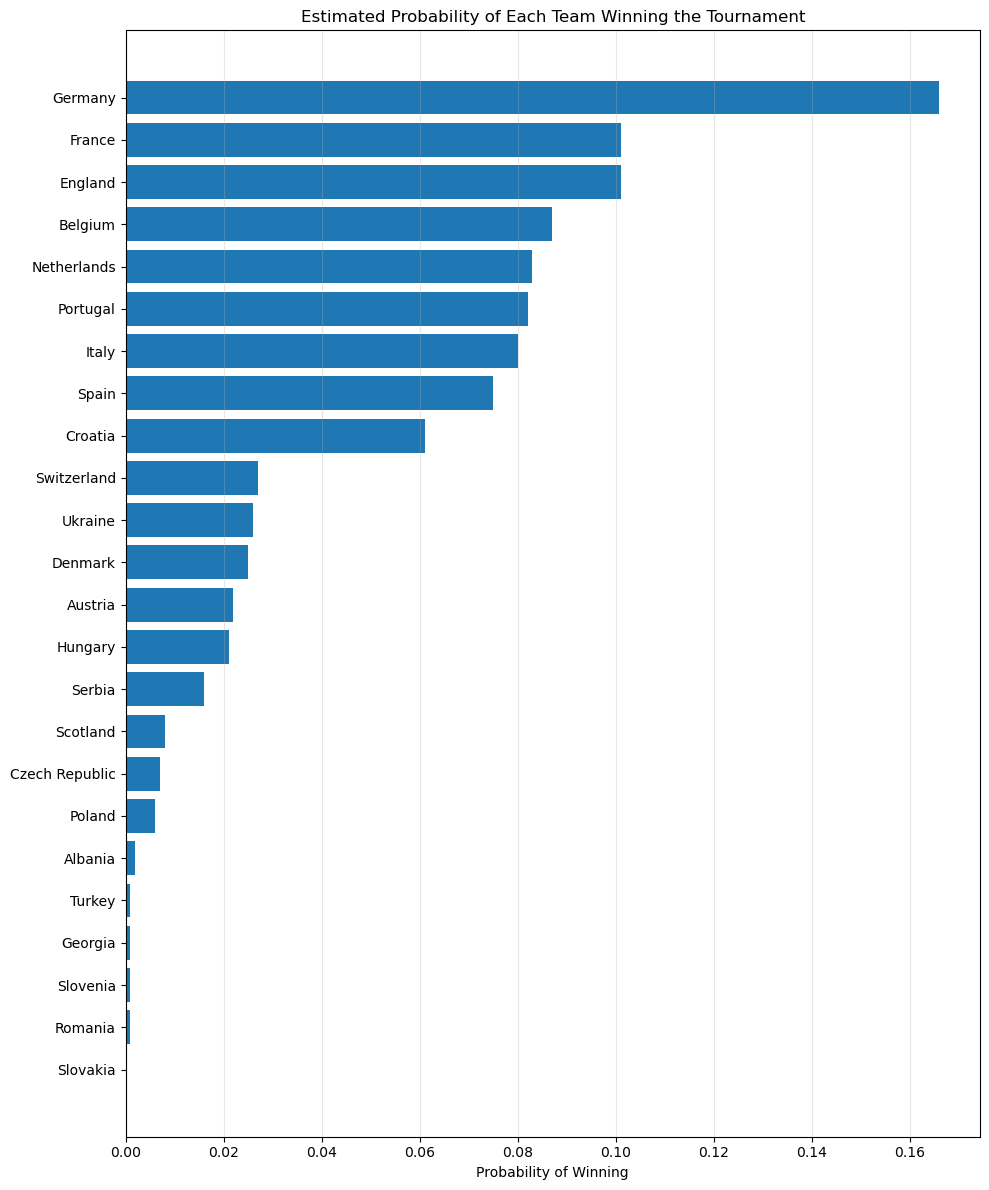

In [25]:
#visualisation (using champion as the only indicator of winning probability)
import matplotlib.pyplot as plt

# Sort by probability for easier reading
Winner_sorted = Winner.sort_values('pWins', ascending=True)

fig, ax = plt.subplots(figsize=(10, 12))
ax.barh(Winner_sorted['Team'], Winner_sorted['pWins'])
ax.set_xlabel('Probability of Winning')
ax.set_title('Estimated Probability of Each Team Winning the Tournament')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

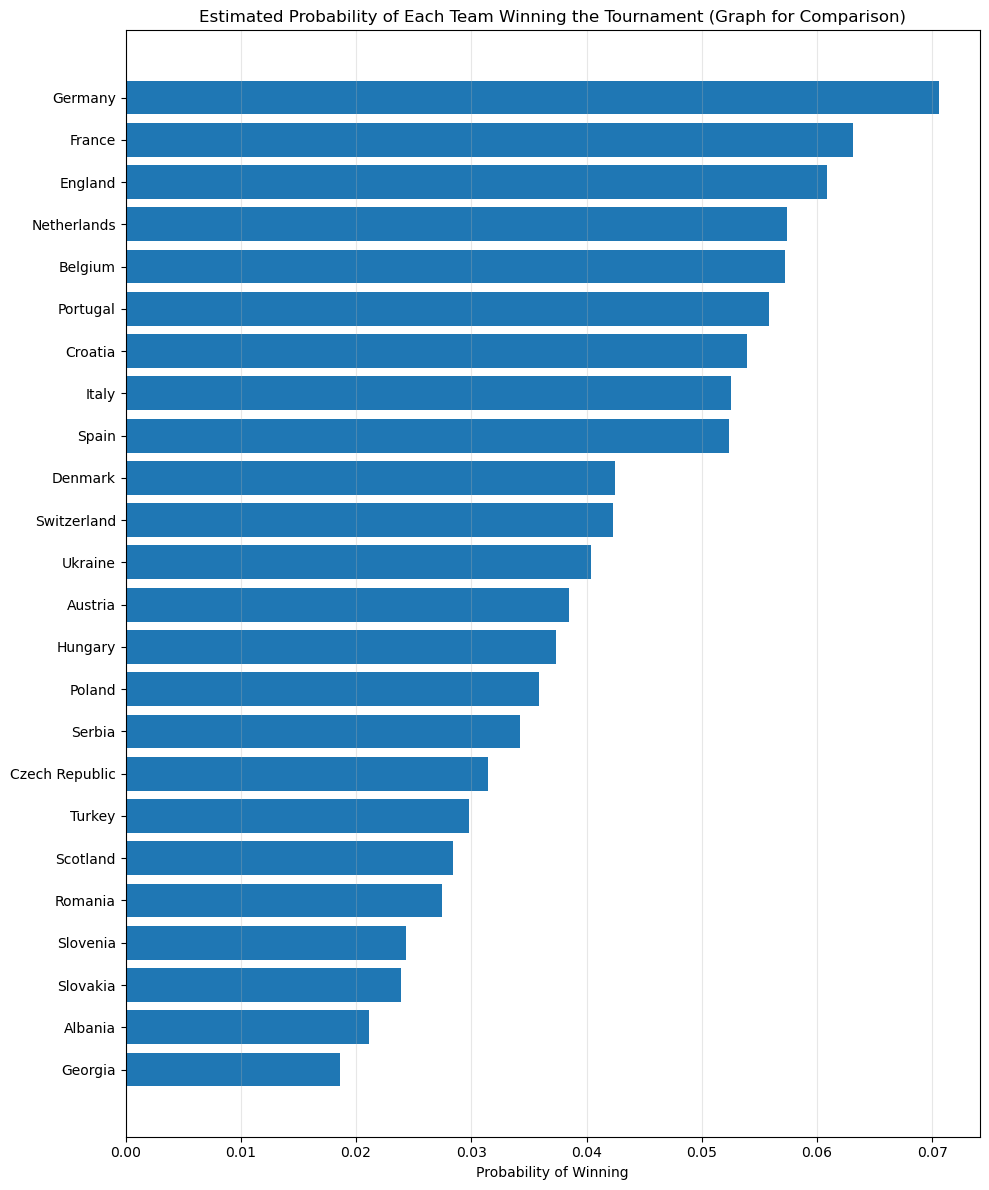

In [26]:
##visualisation & comparison (using number of matches won as the indicator of winning probability)
winCounts_sorted = winCounts.sort_values('pWins', ascending=True)

fig, ax = plt.subplots(figsize=(10, 12))
ax.barh(winCounts_sorted['Team'], winCounts_sorted['pWins'])
ax.set_xlabel('Probability of Winning')
ax.set_title('Estimated Probability of Each Team Winning the Tournament (Graph for Comparison)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
results = pd.read_csv('data/2024_results.csv')

In [28]:
## coverting results to weights for easier comparison
##weights = the number of matches each team have to win to reach this stage
weights = {
    'Group stage': 0,
    'Round of 16': 1,
    'Quarter-finals': 2,
    'Semi-finals': 3,
    'Runner up': 4,
    'Winner': 5
}

# normalisation for a comparable result
results['Weight'] = results['Result'].map(weights)
results['pActual'] = results['Weight'] / results['Weight'].sum()

winCounts_sorted.insert(3, "pActual", [0.0]*24) 

for team, pActual in zip(results['Team'], results['pActual']):
    for name in winCounts_sorted['Team']:
        if team == name:
            winCounts_sorted.loc[winCounts_sorted['Team'] == name, 'pActual'] = pActual


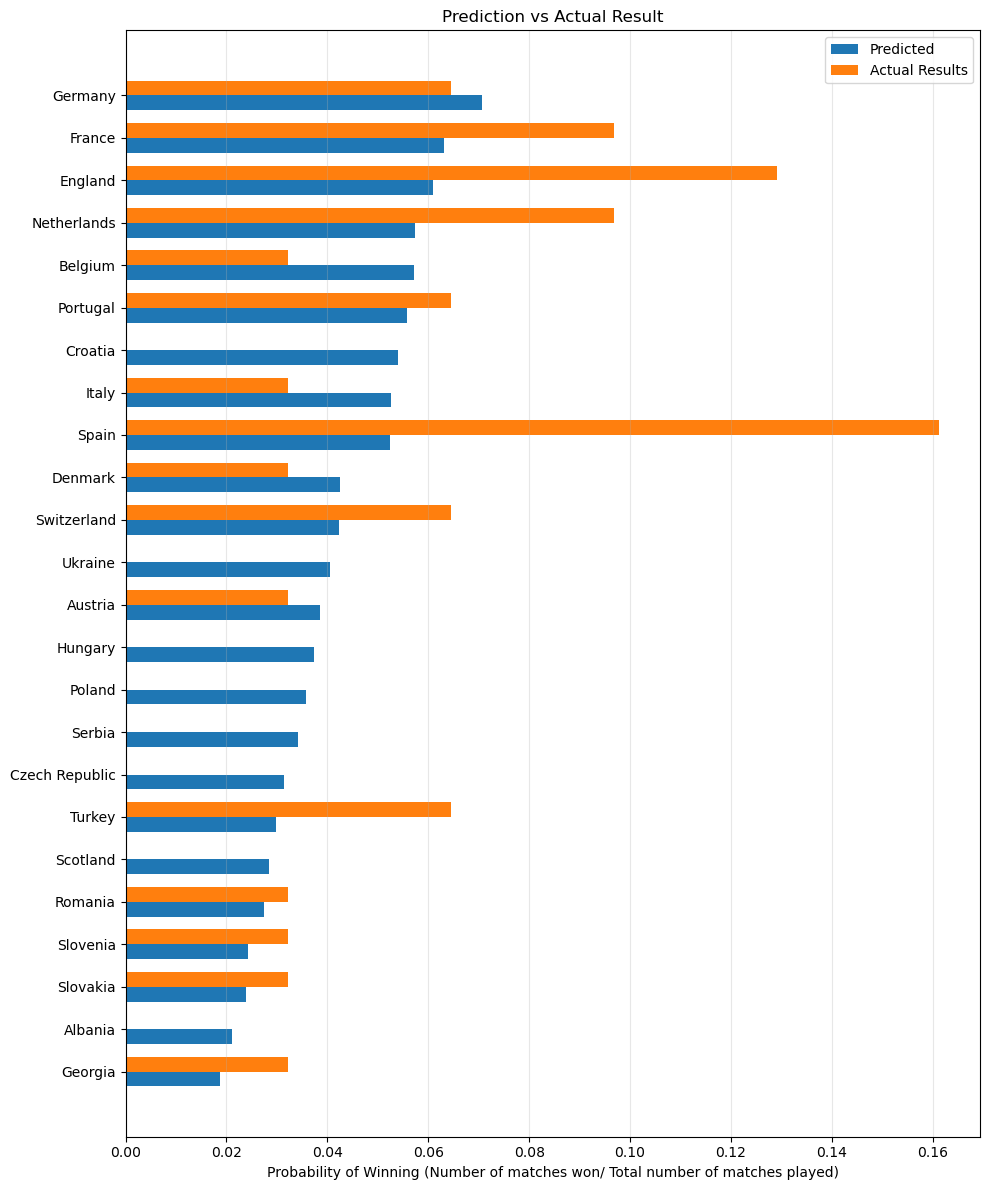

In [29]:
## visualise comparison
fig, ax = plt.subplots(figsize=(10, 12))
y = range(len(winCounts_sorted))
width = 0.35
bar1 = ax.barh([i - width/2 for i in y], winCounts_sorted['pWins'], width, label = 'Predicted')
bar2 = ax.barh([i + width/2 for i in y], winCounts_sorted['pActual'], width, label = 'Actual Results')

ax.set_yticks(y)
ax.set_yticklabels(winCounts_sorted['Team'])

ax.set_xlabel('Probability of Winning (Number of matches won/ Total number of matches played)')
ax.set_title('Prediction vs Actual Result')
ax.legend()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()
